In [ ]:
# We chose Ahya as an example for cell type annotation

import scanpy as sc

adata = sc.read_h5ad("/home/users/Ruijie/scRNAseq/cross_species/h5ad_data/20260424_fixed_leiden_h5ad/Ahya_lei_mc.h5ad")

print(adata)

print("obs:", adata.obs.head())       
print("var:", adata.var.head())       
print("obsm:", adata.obsm.keys())     
print("layers:", adata.layers.keys()) 
print("uns:", adata.uns.keys())       

AnnData object with n_obs × n_vars = 3727 × 29342
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'RNA_snn_res.0.6', 'seurat_clusters', 'pANN_0.25_0.17_410', 'DF.classifications_0.25_0.17_410', 'DF.classifications_0.25_0.17_371', 'Doublet', 'nCount_SCT', 'nFeature_SCT', 'leiden', 'metacell'
    var: 'vf_vst_counts_mean', 'vf_vst_counts_variance', 'vf_vst_counts_variance.expected', 'vf_vst_counts_variance.standardized', 'vf_vst_counts_variable', 'vf_vst_counts_rank', 'var.features', 'var.features.rank'
    uns: 'neighbors'
    obsm: 'X_tsne', 'X_umap'
    obsp: 'distances'
obs:                                      orig.ident  nCount_RNA  nFeature_RNA  \
TTCCTGTTGTGACAAGCTCCTCAAGAACTA  coral_corrected  544.921921           223   
TTGGTCTCAGCCACCGCTTAACGGCAAGCA  coral_corrected  508.303749           349   
GTTGGTCATCATGTAACCGGTACGTCTGGT  coral_corrected  451.915534           361   
CTCGATTCATAAGCCTGGACCTCTTGTATC  coral_corrected  509.257144           370   
TAATCGCACA

/home/users/Ruijie/anaconda3/envs/SAMap/lib/python3.9/site-packages/anndata/compat/__init__.py:329: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  warn(


In [2]:
adata.obs["leiden"].unique()

array(['18', '30', '8', '21', '20', '13', '31', '9', '34', '14', '26',
       '17', '33', '27', '28', '16', '5', '19', '12', '15', '35', '6',
       '22', '4', '24', '25', '32', '29', '3', '1', '36', '2', '23', '7',
       '11', '10'], dtype=object)

In [3]:
adata.var_names = adata.var_names.str.replace('-', '_', regex=False)
import anndata  
adata.raw = anndata.AnnData(adata.X.copy(), obs=adata.obs.copy(), var=adata.var.copy())


In [ ]:
print(adata.obs.columns)

adata.obs = adata.obs.rename(columns={"leiden": "cell_type"})
adata.__dict__['_raw'].__dict__['_var'] = adata.__dict__['_raw'].__dict__['_var'].rename(columns={'_index': 'features'})


print(adata.obs.columns)

adata.write("Ahya_leiden_metacell_data.h5ad")

Index(['orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito',
       'RNA_snn_res.0.6', 'seurat_clusters', 'pANN_0.25_0.17_410',
       'DF.classifications_0.25_0.17_410', 'DF.classifications_0.25_0.17_371',
       'Doublet', 'nCount_SCT', 'nFeature_SCT', 'leiden', 'metacell'],
      dtype='object')
Index(['orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito',
       'RNA_snn_res.0.6', 'seurat_clusters', 'pANN_0.25_0.17_410',
       'DF.classifications_0.25_0.17_410', 'DF.classifications_0.25_0.17_371',
       'Doublet', 'nCount_SCT', 'nFeature_SCT', 'cell_type', 'metacell'],
      dtype='object')


In [5]:
from samap.mapping import SAMAP
from samap.analysis import (get_mapping_scores, GenePairFinder,
                            sankey_plot, chord_plot, CellTypeTriangles, 
                            ParalogSubstitutions, FunctionalEnrichment,
                            convert_eggnog_to_homologs, GeneTriangles)
from samalg import SAM
import pandas as pd

## Loading in raw data

In [6]:
fn1 = './Ahya_leiden_metacell_data.h5ad'
fn2 = '/home/users/Ruijie/tools/samap_directory/workplace/base_25_spis/Spis_25_nature.h5ad'

In [7]:
filenames = {'ah':fn1,'sp':fn2}

In [8]:
sm = SAMAP(
        filenames,
        f_maps = '/home/users/Ruijie/tools/samap_directory/extend_longest_maps/',
        save_processed=True ,
        keys = {'ah':'cell_type','sp':'cell_type'},
    )
sm.run(neigh_from_keys = {'ah':True,'sp':True})

Processing data ah from:
./Ahya_leiden_metacell_data.h5ad
RUNNING SAM
Iteration: 0, Convergence: 1.0
Iteration: 1, Convergence: 0.8721424675411776
Iteration: 2, Convergence: 0.010732218454457676
Computing the UMAP embedding...


/home/users/Ruijie/anaconda3/envs/SAMap/lib/python3.9/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Elapsed time: 39.4599347114563 seconds
Not updating the manifold...
Processing data sp from:
/home/users/Ruijie/tools/samap_directory/workplace/base_25_spis/Spis_25_nature.h5ad
RUNNING SAM
Iteration: 0, Convergence: 1.0
Iteration: 1, Convergence: 0.8523340117569858
Iteration: 2, Convergence: 0.011597141278729723
Computing the UMAP embedding...


/home/users/Ruijie/anaconda3/envs/SAMap/lib/python3.9/site-packages/umap/umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


Elapsed time: 244.35215187072754 seconds
Not updating the manifold...
20580 `ah` gene symbols match between the datasets and the BLAST graph.
21248 `sp` gene symbols match between the datasets and the BLAST graph.
Prepping datasets for translation.
Translating feature spaces pairwise.
Projecting data into joint latent space. 20.691677808761597
Correcting data with means. 30.641592979431152
Expanding neighbourhoods of species ah...
Expanding neighbourhoods of species sp...
Indegree coarsening
Rescaling edge weights by expression correlations.
Concatenating SAM objects...
Iteration 1 complete.
Alignment scores:
          ah        sp
ah  0.000000  0.601889
sp  0.538766  0.000000
Calculating gene-gene correlations in the homology graph...
Prepping datasets for translation.
Translating feature spaces pairwise.
Projecting data into joint latent space. 15.893868207931519
Correcting data with means. 17.396119356155396
Expanding neighbourhoods of species ah...
Expanding neighbourhoods of speci

In [9]:
sm.sams['ah'].adata.obs['cell_type'].head()

TTCCTGTTGTGACAAGCTCCTCAAGAACTA    18
TTGGTCTCAGCCACCGCTTAACGGCAAGCA    30
GTTGGTCATCATGTAACCGGTACGTCTGGT    18
CTCGATTCATAAGCCTGGACCTCTTGTATC    30
TAATCGCACATACATCGCCAGCACAGATTA    18
Name: cell_type, dtype: category
Categories (36, object): ['1', '2', '3', '4', ..., '33', '34', '35', '36']

In [10]:
sm.sams['sp'].adata.obs['cell_type'].head()

Spis01_STP_AAACCCAAGACAGCGT-1                 gastrodermis
Spis01_STP_AAACCCAAGCCTGTGC-1                   neuron_Isl
Spis01_STP_AAACCCAAGGTCGTCC-1                 gastrodermis
Spis01_STP_AAACCCACAAAGGGTC-1    gastrodermis_alga_hosting
Spis01_STP_AAACCCACACACACTA-1                    epidermis
Name: cell_type, dtype: category
Categories (25, object): ['calicoblast', 'cnidocyte', 'digestive_filaments', 'epidermis', ..., 'neuron_Pou4_2', 'neuron_Pou4_Gsx', 'neuron_Pou4_Otp', 'neurosecretory_progenitors']

In [11]:
sm.run(pairwise=True)
samap = sm.samap # SAM object with three species stitched together

Calculating gene-gene correlations in the homology graph...
Prepping datasets for translation.
Translating feature spaces pairwise.
Projecting data into joint latent space. 6.6372644901275635
Correcting data with means. 7.016863822937012
Expanding neighbourhoods of species ah...
Expanding neighbourhoods of species sp...
Indegree coarsening
0/1 (0, 18780)
Rescaling edge weights by expression correlations.
Concatenating SAM objects...
Iteration 1 complete.
Alignment scores:
          ah        sp
ah  0.000000  0.714232
sp  0.616036  0.000000
Calculating gene-gene correlations in the homology graph...
Prepping datasets for translation.
Translating feature spaces pairwise.
Projecting data into joint latent space. 4.885963678359985
Correcting data with means. 15.63816237449646
Expanding neighbourhoods of species ah...
Expanding neighbourhoods of species sp...
Indegree coarsening
0/1 (0, 18780)
Rescaling edge weights by expression correlations.
Concatenating SAM objects...
Iteration 2 comple

<Axes: >

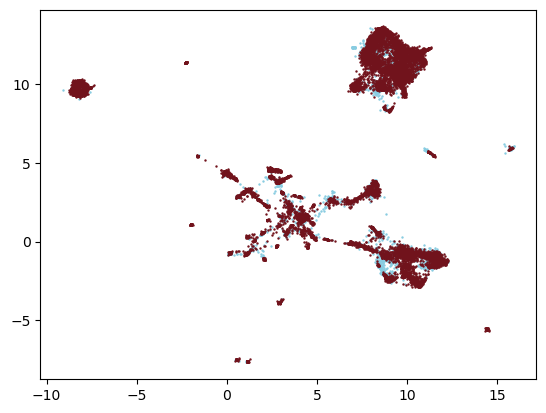

In [12]:
sm.scatter()

In [13]:
import pickle
with open('./sm_ahya_spis.pkl', 'wb') as file:
    pickle.dump(sm, file)
print("对象已保存到本地文件。")

对象已保存到本地文件。


Post-SAMap analysis

In [ ]:
import pickle


with open('./sm_ahya_spis.pkl', 'rb') as file:
    sm = pickle.load(file)

print("对象已成功加载。")


对象已成功加载。


In [15]:
import scanpy as sc
import matplotlib.pyplot as plt
import networkx as nx
import umap
from scipy.sparse import csr_matrix
import seaborn as sns
import holoviews as hv

整合UMAP可视化

In [16]:
samap = sm.samap
adata = samap.adata
adata

AnnData object with n_obs × n_vars = 18780 × 62843
    obs: 'ah_orig.ident', 'ah_RNA_snn_res.0.6', 'ah_seurat_clusters', 'ah_DF.classifications_0.25_0.17_410', 'ah_DF.classifications_0.25_0.17_371', 'ah_Doublet', 'ah_cell_type', 'ah_metacell', 'sp_cell_type', 'batch', 'species'
    uns: 'neighbors', 'gnnm_corr', 'mapping_K', 'umap', 'homology_gene_names_dict'
    obsm: 'X_umap'
    layers: 'X_disp'
    obsp: 'connectivities'
    varp: 'homology_graph_reweighted', 'homology_graph'

/home/users/Ruijie/anaconda3/envs/SAMap/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/users/Ruijie/anaconda3/envs/SAMap/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


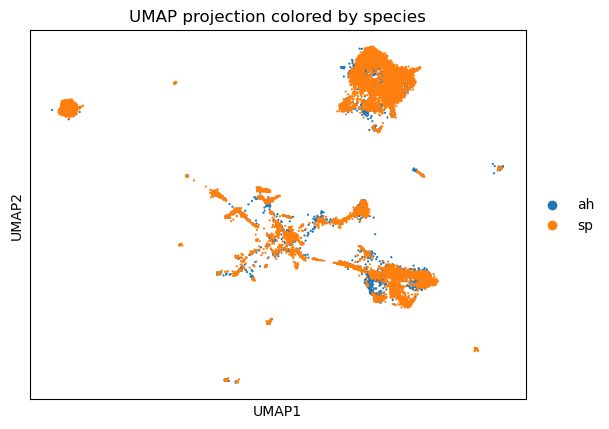

In [17]:
sc.pl.umap(adata, color=['species'], title='UMAP projection colored by species', size=10)

## Calculating cell type mapping scores

sankey_plot

In [ ]:
keys = {'ah':'cell_type','sp':'cell_type'}
D,MappingTable = get_mapping_scores(sm,keys,n_top = 0)
D.head()
MappingTable.head()

sankey_plot(MappingTable, align_thr=0.05, species_order=['ah', 'sp'])


:Sankey   [source,target]   (Value)

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
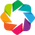

In [19]:
import holoviews as hv
hv.extension('bokeh')

sankey_obj = sankey_plot(MappingTable, align_thr=0.15, species_order=['ah', 'sp'])
sankey_obj
sankey_obj.opts(frame_width=2000, frame_height=1600)
hv.save(sankey_obj, "./sankey_plot.html", resources='inline')

In [20]:
MappingTable.index

Index(['ah_1', 'ah_10', 'ah_11', 'ah_12', 'ah_13', 'ah_14', 'ah_15', 'ah_16',
       'ah_17', 'ah_18', 'ah_19', 'ah_2', 'ah_20', 'ah_21', 'ah_22', 'ah_23',
       'ah_24', 'ah_25', 'ah_26', 'ah_27', 'ah_28', 'ah_29', 'ah_3', 'ah_30',
       'ah_31', 'ah_32', 'ah_33', 'ah_34', 'ah_35', 'ah_36', 'ah_4', 'ah_5',
       'ah_6', 'ah_7', 'ah_8', 'ah_9', 'sp_calicoblast', 'sp_cnidocyte',
       'sp_digestive_filaments', 'sp_epidermis', 'sp_gastrodermis',
       'sp_gastrodermis_alga_hosting', 'sp_gastrodermis_like_2',
       'sp_gastrodermis_muscle', 'sp_germline_oocytes_1',
       'sp_germline_oocytes_2', 'sp_gland_1_Xbp', 'sp_gland_2', 'sp_gland_3',
       'sp_immune_macrophage', 'sp_immune_macrophage_like_1',
       'sp_immune_macrophage_like_2', 'sp_immune_nascent', 'sp_neuron_Atoh8',
       'sp_neuron_Isl', 'sp_neuron_Isl_Nkx6', 'sp_neuron_Pou4_1',
       'sp_neuron_Pou4_2', 'sp_neuron_Pou4_Gsx', 'sp_neuron_Pou4_Otp',
       'sp_neurosecretory_progenitors'],
      dtype='object')

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

gf_rows = MappingTable.index[MappingTable.index.str.startswith('ah_')]
sp_cols = MappingTable.columns[MappingTable.columns.str.startswith('sp_')]

def sort_gf_index(gf_list):
    def extract_number(x):
        try:
            return int(x.split('_')[1])
        except (IndexError, ValueError):
            return 0

    return sorted(gf_list, key=extract_number)

gf_rows_sorted = sort_gf_index(gf_rows.tolist())

FilteredMappingTable = MappingTable.loc[gf_rows_sorted, sp_cols]

print(FilteredMappingTable.head())

sns.set(style="white")

plt.figure(figsize=(20, 15))

sns.heatmap(
    FilteredMappingTable,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={"label": "Similarity Score"},
    annot_kws={"size": 8},
)

plt.title("Similarity Heatmap between Clusters", fontsize=18)
plt.xlabel("Clusters", fontsize=16)
plt.ylabel("Clusters", fontsize=16)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.savefig("./ah_vs_sp_heatmap.pdf", format="pdf", bbox_inches="tight")

plt.show()

In [ ]:
def export_mapping_table_for_sankey(mapping_table, output_file='mapping_table.csv'):

    if not isinstance(mapping_table, pd.DataFrame):
        raise ValueError("mapping_table must be a pandas DataFrame")
    

    mapping_table.to_csv(output_file, index=True, header=True)
    print(f"Mapping table exported to {output_file}")
    print(f"Table shape: {mapping_table.shape}")
    print(f"Sample of the data:")
    print(mapping_table.iloc[:5, :5])
    
    return output_file


export_mapping_table_for_sankey(FilteredMappingTable, 'ahsp_samap_mapping_table.csv')

Mapping table exported to ahsp_samap_mapping_table.csv
Table shape: (36, 25)
Sample of the data:
      sp_calicoblast  sp_cnidocyte  sp_digestive_filaments  sp_epidermis  \
ah_1        0.000430      0.003931                0.023994      0.001039   
ah_2        0.042602      0.003424                0.029871      0.576158   
ah_3        0.823353      0.004187                0.015110      0.012412   
ah_4        0.000000      0.000000                0.002655      0.002735   
ah_5        0.021969      0.002280                0.026940      0.749863   

      sp_gastrodermis  
ah_1         0.718176  
ah_2         0.000590  
ah_3         0.009846  
ah_4         0.027504  
ah_5         0.003051  


'ahsp_samap_mapping_table.csv'